# Pruebas por partes del pipeline

Este cuaderno prueba cada componente del detector por separado, en el mismo orden en que los datos recorren el pipeline:

| # | Parte | Entrada → salida |
|---|---|---|
| 1 | Preprocesamiento facial | fotograma → rostro 224×224×3 |
| 2 | Mapa diferencial bilateral | rostro → \|flip(izq) − der\| 224×112×3 |
| 3 | PatchEmbed | (1,3,224,224) → (1,3136,96) |
| 4 | Partición en ventanas | 56×56 → 64 ventanas de 7×7 |
| 5 | Ventanas desplazadas y máscara | máscara (64,49,49) |
| 6 | Window Attention | (64,49,96) → (64,49,96) |
| 7 | Patch Merging | 56×56×96 → 28×28×192 |
| 8 | Swin completo por etapas | rostro → 768 → 256 |
| 9 | CNN lateral | (1,3,224,112) → 256 |
| 10 | Fusión y Branch Dropout | 256 + 256 → 512 |
| 11 | Clasificador MLP | 512 → 2 |
| 12 | Focal Loss | logits → pérdida y gradiente |
| 13 | Detector completo | rostro + mapa → P(deepfake) por video |
| 14 | Aprendizaje (sobreajuste controlado) | la pérdida debe bajar |
| 15 | Aumento de calidad y normalización | degradaciones y estadísticos de train |
| 16 | Partición sin fugas | train/val/test por identidad |
| 17 | Métricas | AUC, F1, precisión, recall, matriz de confusión |
| 18 | Gradientes numéricos | backprop manual = diferencias finitas |

Cada prueba imprime las dimensiones y termina con una comprobación `OK` o `FALLA`. La última celda muestra la tabla con todas.

Las pruebas usan un video real de FaceForensics++, indicado en la variable de entorno `RUTA_ROSTRO` (por ejemplo `original_sequences/youtube/c23/videos/003.mp4`), y el modelo de MediaPipe en `RUTA_LANDMARKER`. Sin ruta, se usa un rostro sintético dibujado en código.

## 0 Configuración

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt

# Ubicación de los módulos: ../src desde el repositorio o el clon en Kaggle.
for cand in ("../src", "src", "/kaggle/working/deteccion-deepfakes-swin/src"):
    if os.path.isdir(cand) and os.path.exists(os.path.join(cand, "swin.py")):
        SRC = os.path.abspath(cand)
        break
else:
    raise FileNotFoundError("No encuentro la carpeta src/. Clona el repositorio o ajusta la ruta.")
sys.path.insert(0, SRC)

import backend as bk
from backend import xp

SEED = 42
bk.set_seed(SEED)
RUTA_ROSTRO = os.environ.get("RUTA_ROSTRO")   # imagen o video con un rostro; None usa el rostro sintético
RUTA_LANDMARKER = os.environ.get("RUTA_LANDMARKER", "face_landmarker.task")   # modelo de MediaPipe
CARGAR_IMAGENET = False     # True descarga los pesos de Swin-T (necesita internet)
FIG_DIR = "figuras_pruebas"
os.makedirs(FIG_DIR, exist_ok=True)

RESULTADOS = []


def comprobar(nombre: str, condicion: bool, detalle: str = "") -> None:
    ok = bool(condicion)
    RESULTADOS.append((nombre, ok, detalle))
    print(f"[{'OK   ' if ok else 'FALLA'}] {nombre}" + (f"  ({detalle})" if detalle else ""))


def forma(a) -> tuple:
    return tuple(int(d) for d in a.shape)


print("Módulos:", SRC)
print("Backend:", "CuPy (GPU)" if bk.ON_GPU else "NumPy (CPU)", "| dtype:", bk.DTYPE.__name__, "| semilla:", SEED)

Módulos: ../src
Backend: NumPy (CPU) | dtype: float32 | semilla: 42


## 1 Preprocesamiento facial: de fotograma a rostro 224×224

Con un rostro real se usa `FaceAligner` (MediaPipe FaceMesh):
1. Detecta 468 puntos faciales.
2. Rota el fotograma para nivelar los ojos.
3. Centra el recorte en la línea media de los ojos (x) y entre frente y mentón (y).
4. Recorta un cuadrado con margen de 1.35 y lo lleva a 224×224.

Sin ruta se dibuja un rostro sintético frontal y casi simétrico, con textura de piel.

  video: 003.mp4 | 303 fotogramas | se usa el fotograma 101


  fotograma: 640x480 | landmarks: 478 puntos
  ángulo corregido: -7.52°  | índice de giro: -0.049
Origen: FaceForensics++ (003.mp4), alineado con MediaPipe
  rostro (H, W, C): (224, 224, 3) uint8
  tensor de entrada: (1, 3, 224, 224) float32 rango [0.004, 0.961]


[ERROR:0@0.159] global persistence.cpp:584 open Can't open file: '/usr/local/lib/python3.13/site-packages/cv2/data/haarcascade_frontalface_default.xml' in read mode
W0000 00:00:1795210249.870809     285 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1795210249.879622     286 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795210249.899942     286 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


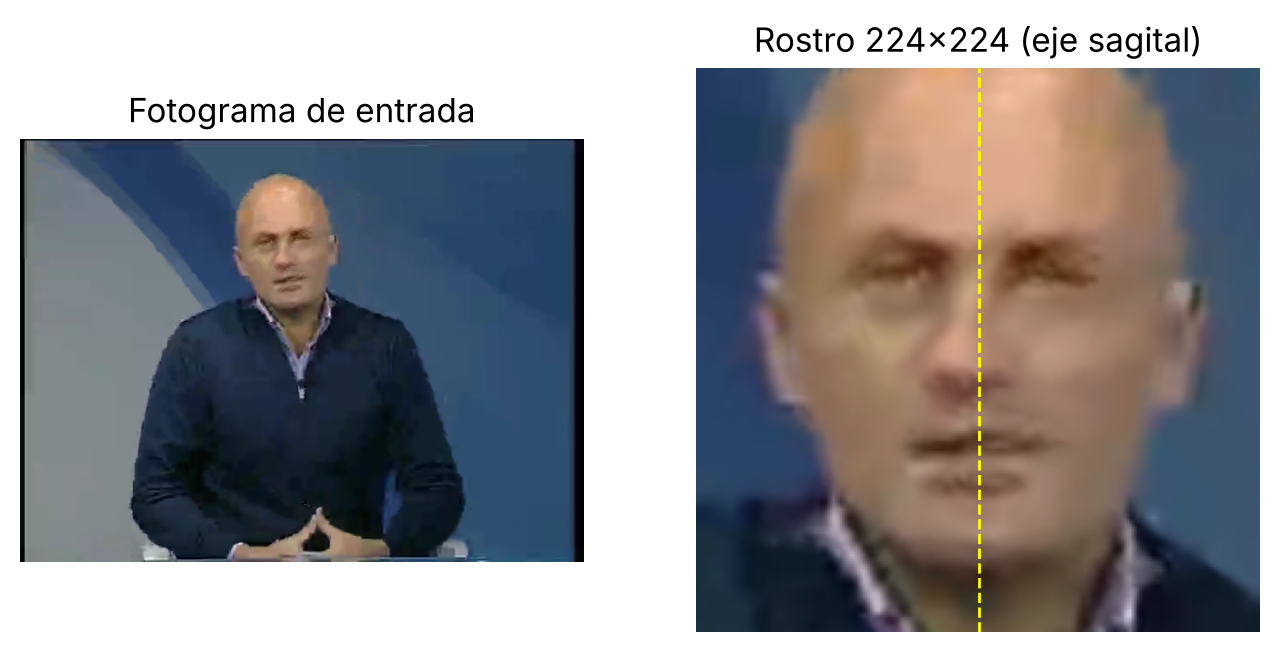

[OK   ] 1 Preprocesamiento  ((1,3,224,224) en [0,1])


In [2]:
import cv2


def rostro_sintetico(size: int = 224, seed: int = SEED) -> np.ndarray:
    rng = np.random.RandomState(seed)
    img = np.full((size, size, 3), (70, 80, 95), np.uint8)
    c = size // 2
    cv2.ellipse(img, (c, c + 6), (70, 92), 0, 0, 360, (190, 150, 125), -1)
    cv2.ellipse(img, (c, c - 70), (74, 34), 0, 180, 360, (45, 35, 30), -1)
    for dx in (-30, 30):
        cv2.ellipse(img, (c + dx, c - 15), (14, 7), 0, 0, 360, (245, 245, 245), -1)
        cv2.circle(img, (c + dx, c - 15), 5, (60, 40, 30), -1)
        cv2.line(img, (c + dx - 15, c - 32), (c + dx + 15, c - 32), (60, 45, 35), 3)
    cv2.line(img, (c, c - 10), (c - 6, c + 22), (160, 115, 95), 2)
    cv2.line(img, (c - 6, c + 22), (c + 6, c + 22), (160, 115, 95), 2)
    cv2.ellipse(img, (c, c + 45), (22, 8), 0, 0, 180, (150, 70, 70), 3)
    textura = cv2.GaussianBlur(rng.normal(0, 6, (size, size)).astype(np.float32), (0, 0), 0.8)[..., None]
    return np.clip(img.astype(np.float32) + textura, 0, 255).astype(np.uint8)


ES_VIDEO = bool(RUTA_ROSTRO) and RUTA_ROSTRO.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))


def leer_fotograma(ruta, pos):
    cap = cv2.VideoCapture(ruta)
    cap.set(cv2.CAP_PROP_POS_FRAMES, pos)
    ok, frame = cap.read()
    cap.release()
    assert ok, f"No pude leer el fotograma {pos} de {ruta}"
    return frame


def cargar_rostro(ruta):
    from data import FaceAligner
    if ES_VIDEO:
        n = int(cv2.VideoCapture(ruta).get(cv2.CAP_PROP_FRAME_COUNT))
        frame = leer_fotograma(ruta, n // 3)
        print(f"  video: {os.path.basename(ruta)} | {n} fotogramas | se usa el fotograma {n // 3}")
    else:
        frame = cv2.imread(ruta)
        assert frame is not None, f"No pude leer {ruta}"
    aligner = FaceAligner(output_size=224, task_model_path=RUTA_LANDMARKER)
    face, info = aligner.align(frame)
    aligner.close()
    assert face is not None, "MediaPipe no encontró un rostro"
    print(f"  fotograma: {frame.shape[1]}x{frame.shape[0]} | landmarks: {len(info['landmarks'])} puntos")
    print(f"  ángulo corregido: {info['angle']:.2f}°  | índice de giro: {info['yaw']:+.3f}")
    return frame[..., ::-1], face


if RUTA_ROSTRO:
    frame_rgb, face_rgb = cargar_rostro(RUTA_ROSTRO)
    origen = f"FaceForensics++ ({os.path.basename(RUTA_ROSTRO)}), alineado con MediaPipe"
else:
    face_rgb = rostro_sintetico()
    frame_rgb = face_rgb
    origen = "rostro sintético"

face_input = bk.asarray(face_rgb.transpose(2, 0, 1)[None] / 255.0)   # (1, 3, 224, 224)
print("Origen:", origen)
print("  rostro (H, W, C):", face_rgb.shape, face_rgb.dtype)
print("  tensor de entrada:", forma(face_input), face_input.dtype,
      f"rango [{float(face_input.min()):.3f}, {float(face_input.max()):.3f}]")

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(frame_rgb); ax[0].set_title("Fotograma de entrada")
ax[1].imshow(face_rgb); ax[1].axvline(112, color="yellow", ls="--", lw=1); ax[1].set_title("Rostro 224×224 (eje sagital)")
for a in ax: a.axis("off")
fig.savefig(f"{FIG_DIR}/p01_preprocesamiento.png", dpi=300, bbox_inches="tight"); plt.show()

comprobar("1 Preprocesamiento", forma(face_input) == (1, 3, 224, 224) and 0 <= float(face_input.min())
          and float(face_input.max()) <= 1, "(1,3,224,224) en [0,1]")

## 2 Mapa diferencial bilateral

El rostro se divide en dos hemicaras de 224×112. La izquierda se refleja y se resta de la derecha: $|flip(I_{izq}) - I_{der}|$.

Hay dos modos en `bilateral_diff_map`:
- `pixel`: la resta directa del diseño original.
- `residual` (el que se usa ahora): antes de restar, quita a cada hemicara su versión desenfocada (σ=1) y la normaliza por su energía. Así el mapa mide diferencias de **textura** y no de pose o iluminación.

Comprobaciones:
- Un rostro perfectamente simétrico debe dar un mapa nulo.
- Si se altera una sola mitad (como un blending mal hecho), el mapa debe encenderse justo en esa zona.

Hemicara izquierda: (1, 3, 224, 112) | hemicara derecha: (1, 3, 224, 112)
Mapa por píxeles:  (1, 3, 224, 112) energía media = 0.0586
Mapa de residuos:  (1, 3, 224, 112) energía media = 0.7091
Simétrico exacto: máximo del mapa = 4.43e-05
Con la mejilla derecha alterada: energía dentro de la zona = 0.3534, fuera = 0.0426 (x8)
Fuera de la zona no es cero: al perder textura, la normalización por energía reescala toda la hemicara derecha.


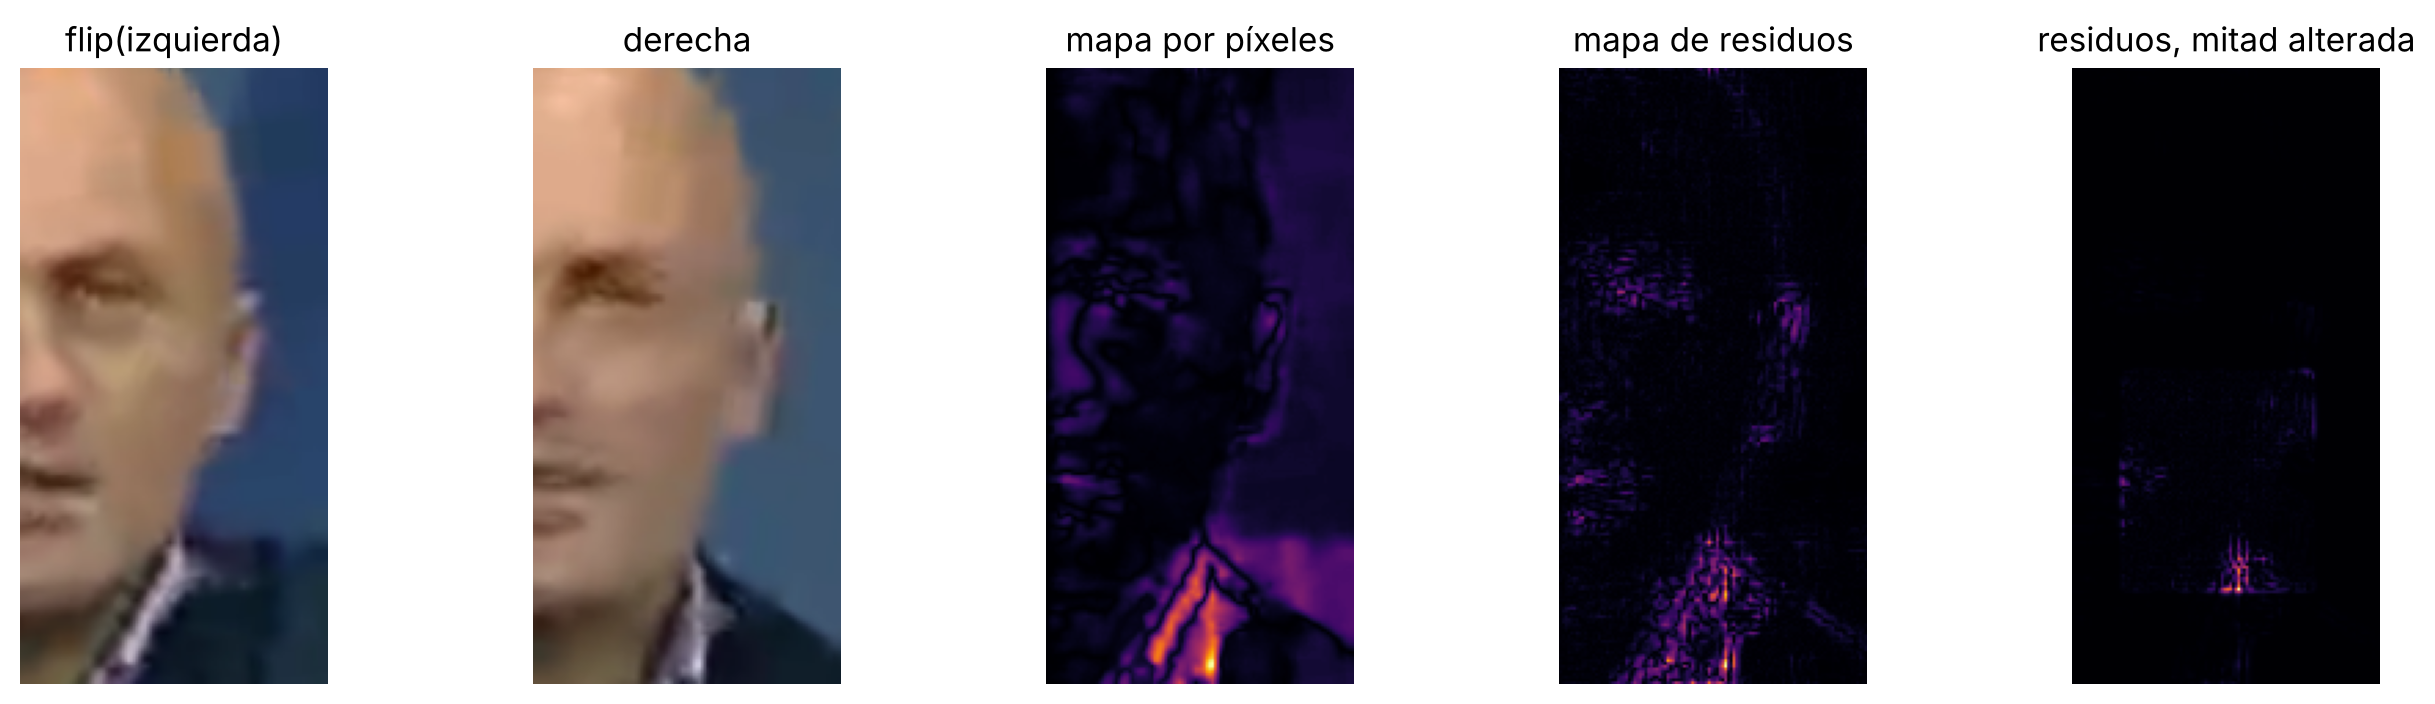

[OK   ] 2a Forma del mapa  ((1,3,224,112))
[OK   ] 2b Rostro simétrico da mapa nulo  (máx 4.4e-05, error de redondeo float32)
[OK   ] 2c El mapa localiza una alteración de un solo lado  (zona alterada x8 más energía que el resto)


In [3]:
from augment import bilateral_diff_map, gaussian_blur

diff_pixel = bilateral_diff_map(face_input, mode="pixel")
diff_res = bilateral_diff_map(face_input, mode="residual", sigma=1.0)
print("Hemicara izquierda:", forma(face_input[..., :112]), "| hemicara derecha:", forma(face_input[..., 112:]))
print("Mapa por píxeles: ", forma(diff_pixel), f"energía media = {float(diff_pixel.mean()):.4f}")
print("Mapa de residuos: ", forma(diff_res), f"energía media = {float(diff_res.mean()):.4f}")



def simetrizar(t):
    der = t[..., t.shape[-1] // 2:]
    return xp.concatenate([der[..., ::-1], der], axis=-1)


# Rostro simétrico exacto: la mitad izquierda es el espejo de la derecha.
simetrico = simetrizar(face_input)
e_sim = float(bilateral_diff_map(simetrico, mode="residual").max())

# Sobre ese rostro simétrico se suaviza solo la mejilla derecha (pérdida de textura típica del blending).
zona = (slice(None), slice(None), slice(110, 190), slice(130, 200))
manip = simetrico.copy()
manip[zona] = gaussian_blur(simetrico, 2.0)[zona]
diff_manip = bilateral_diff_map(manip, mode="residual")
zona_mapa = (slice(None), slice(None), slice(110, 190), slice(130 - 112, 200 - 112))
dentro = float(diff_manip[zona_mapa].mean())
fuera_m = xp.ones(diff_manip.shape, bool); fuera_m[zona_mapa] = False
fuera = float(diff_manip[fuera_m].mean())
print(f"Simétrico exacto: máximo del mapa = {e_sim:.2e}")
print(f"Con la mejilla derecha alterada: energía dentro de la zona = {dentro:.4f}, fuera = {fuera:.4f} (x{dentro / fuera:.0f})")
print("Fuera de la zona no es cero: al perder textura, la normalización por energía reescala toda la hemicara derecha.")

a = lambda t: bk.to_numpy(t[0]).transpose(1, 2, 0)
fig, ax = plt.subplots(1, 5, figsize=(16, 4))
ax[0].imshow(a(face_input[..., :112][..., ::-1])); ax[0].set_title("flip(izquierda)")
ax[1].imshow(a(face_input[..., 112:])); ax[1].set_title("derecha")
ax[2].imshow(a(diff_pixel).mean(-1), cmap="inferno"); ax[2].set_title("mapa por píxeles")
ax[3].imshow(a(diff_res).mean(-1), cmap="inferno"); ax[3].set_title("mapa de residuos")
ax[4].imshow(a(diff_manip).mean(-1), cmap="inferno"); ax[4].set_title("residuos, mitad alterada")
for x in ax: x.axis("off")
fig.savefig(f"{FIG_DIR}/p02_mapa_diferencial.png", dpi=300, bbox_inches="tight"); plt.show()

comprobar("2a Forma del mapa", forma(diff_res) == (1, 3, 224, 112), "(1,3,224,112)")
comprobar("2b Rostro simétrico da mapa nulo", e_sim < 1e-3 * float(diff_res.mean()),
          f"máx {e_sim:.1e}, error de redondeo float32")
comprobar("2c El mapa localiza una alteración de un solo lado", dentro > 5 * fuera,
          f"zona alterada x{dentro / fuera:.0f} más energía que el resto")
diff_input = diff_res

## 3 PatchEmbed: de píxeles a parches de 4×4

La imagen de 224×224 se divide en parches de 4×4. Como 224 / 4 = 56, salen 56×56 = 3136 parches.
Cada parche (4·4·3 = 48 valores) se proyecta a un vector de 96 dimensiones y se normaliza con LayerNorm.

In [4]:
from swin import PatchEmbedSwin

patch_embed = PatchEmbedSwin(img_size=224, patch_size=4, in_chans=3, embed_dim=96)
tokens = patch_embed(face_input)
print("Entrada:", forma(face_input))
print("Parches por lado:", patch_embed.grid, "| valores por parche:", 4 * 4 * 3)
print("Salida (B, tokens, dim):", forma(tokens))

# Debe rechazar una resolución distinta de la configurada.
try:
    patch_embed(bk.randn(1, 3, 220, 220)); rechaza = False
except AssertionError:
    rechaza = True
comprobar("3 PatchEmbed", forma(tokens) == (1, 3136, 96) and rechaza, "(1,3136,96); rechaza 220×220")

Entrada: (1, 3, 224, 224)
Parches por lado: 56 | valores por parche: 48
Salida (B, tokens, dim): (1, 3136, 96)
[OK   ] 3 PatchEmbed  ((1,3136,96); rechaza 220×220)


## 4 Partición en ventanas locales de 7×7

En vez de comparar cada parche con los 3136, Swin agrupa los parches en ventanas de 7×7.
Como 56 / 7 = 8, salen 8×8 = 64 ventanas de 49 parches cada una.
`window_reverse` debe reconstruir exactamente el mapa original.

In [5]:
from swin import window_partition, window_reverse

mapa = tokens.reshape(1, 56, 56, 96)
ventanas = window_partition(mapa, 7)
reconstruido = window_reverse(ventanas, 7, 1, 56, 56)
err = float(xp.abs(reconstruido - mapa).max())
print("Mapa de parches:", forma(mapa))
print("Ventanas (n, 7·7, C):", forma(ventanas))
print(f"Atención global: 3136² = {3136**2:,} pares | por ventanas: 64·49² = {64 * 49**2:,} pares "
      f"(x{3136**2 / (64 * 49**2):.0f} menos)")
print(f"Error de reconstrucción: {err:.1e}")
comprobar("4 Partición y reconstrucción", forma(ventanas) == (64, 49, 96) and err == 0.0, "64 ventanas, error 0")

Mapa de parches: (1, 56, 56, 96)
Ventanas (n, 7·7, C): (64, 49, 96)
Atención global: 3136² = 9,834,496 pares | por ventanas: 64·49² = 153,664 pares (x64 menos)
Error de reconstrucción: 0.0e+00
[OK   ] 4 Partición y reconstrucción  (64 ventanas, error 0)


## 5 Ventanas desplazadas (SW-MSA) y su máscara

Los bloques impares desplazan el mapa 3 posiciones (`roll`) para que las ventanas vecinas se comuniquen.
Tras el desplazamiento, algunas ventanas mezclan regiones que no eran contiguas en la imagen; la máscara pone −100 entre ellas para que no se atiendan.

Máscara (ventanas, 49, 49): (64, 49, 49) | valores: [-100.    0.]
Ventanas con pares bloqueados: 15 de 64 (las del borde derecho e inferior)


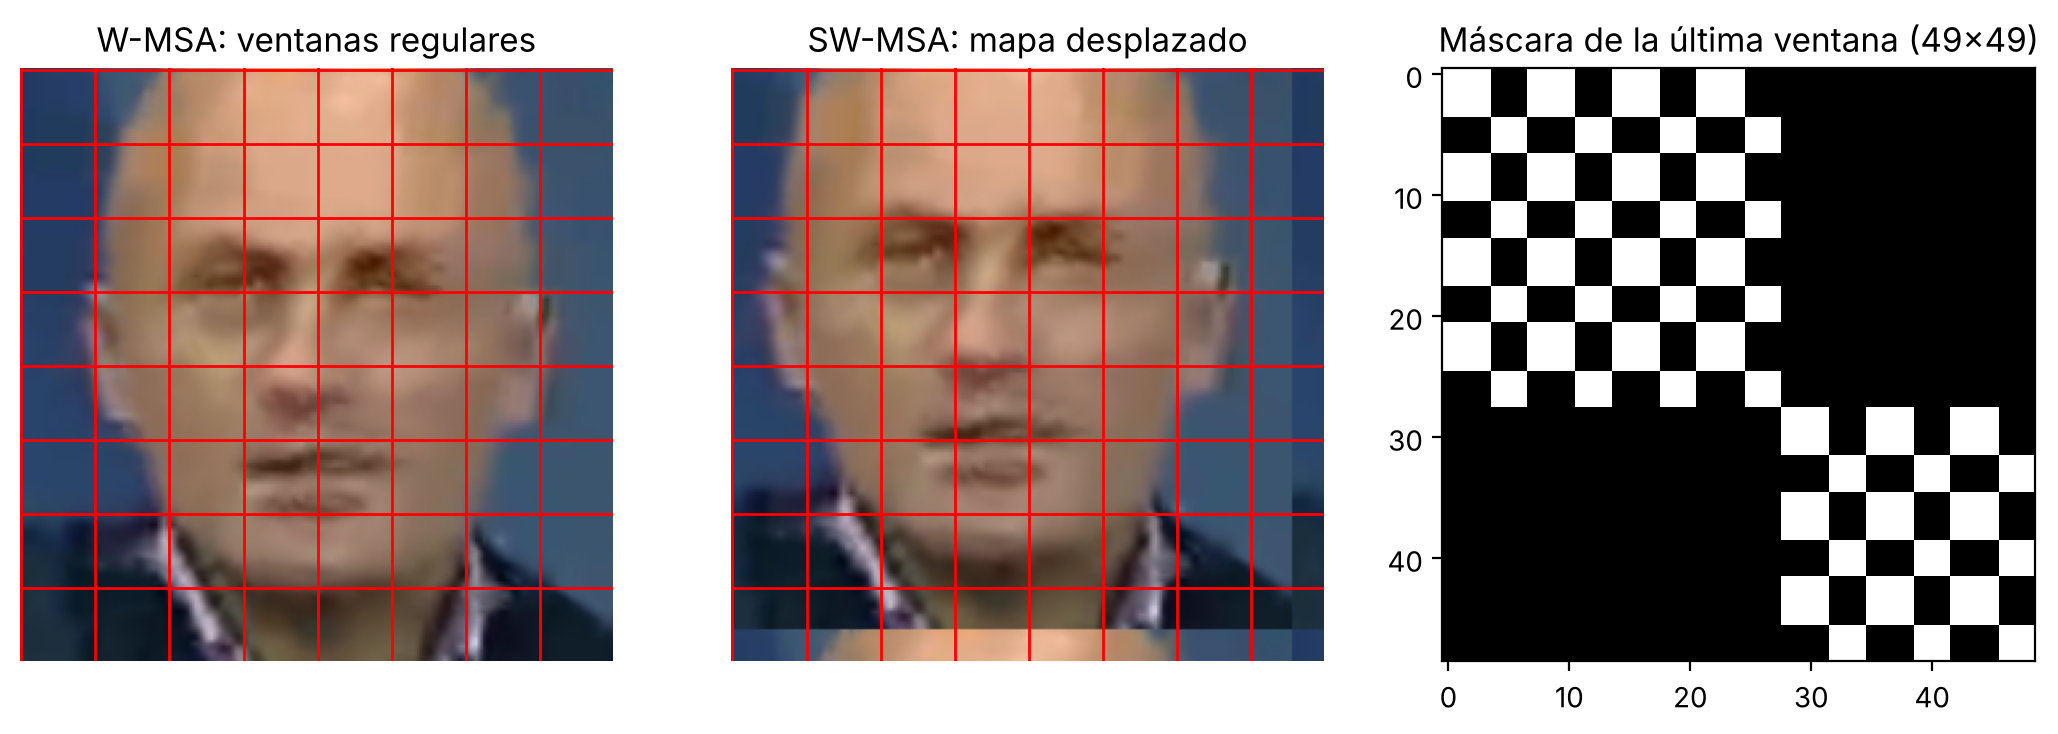

[OK   ] 5 Máscara de ventanas desplazadas  ((64,49,49), valores {0,-100})


In [6]:
from swin import shifted_window_mask

mask = shifted_window_mask(56, 56, 7, 3)
valores = np.unique(mask)
bloqueadas = int((mask.reshape(64, -1) != 0).any(1).sum())
print("Máscara (ventanas, 49, 49):", mask.shape, "| valores:", valores)
print("Ventanas con pares bloqueados:", bloqueadas, "de 64 (las del borde derecho e inferior)")

img_vis = face_rgb.copy()
desplazada = np.roll(img_vis, (-12, -12), axis=(0, 1))
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
for k, (im, t) in enumerate(((img_vis, "W-MSA: ventanas regulares"), (desplazada, "SW-MSA: mapa desplazado"))):
    ax[k].imshow(im); ax[k].set_title(t)
    for p in range(0, 224, 28):
        ax[k].axhline(p, color="red", lw=1); ax[k].axvline(p, color="red", lw=1)
    ax[k].axis("off")
ax[2].imshow(mask[63], cmap="gray"); ax[2].set_title("Máscara de la última ventana (49×49)")
fig.savefig(f"{FIG_DIR}/p05_ventanas_desplazadas.png", dpi=300, bbox_inches="tight"); plt.show()

comprobar("5 Máscara de ventanas desplazadas", mask.shape == (64, 49, 49) and set(valores) == {0.0, -100.0}
          and mask[0].max() == 0, "(64,49,49), valores {0,-100}")

## 6 Window Attention con sesgo de posición relativa

Atención multi-cabeza dentro de cada ventana, más una tabla aprendida de sesgos por posición relativa:
con ventanas de 7 hay (2·7−1)² = 169 desplazamientos posibles por cabeza.

In [7]:
from layers import softmax
from swin import WindowAttention

attn = WindowAttention(dim=96, window=7, num_heads=3)
x_win = ventanas
y_win = attn(x_win)
filas = bk.to_numpy(attn.attn.sum(-1))
print("Entrada:", forma(x_win), "| salida:", forma(y_win))
print("Tabla de sesgo relativo:", forma(attn.bias_table.data), "| mapa de atención:", forma(attn.attn))

y_mask = attn(x_win, bk.asarray(shifted_window_mask(56, 56, 7, 3)))
fuga = float(attn.attn[63][:, mask[63] < 0].max())
print(f"Suma de cada fila de atención: {filas.min():.6f} a {filas.max():.6f}")
print(f"Atención máxima entre regiones bloqueadas: {fuga:.1e}")
comprobar("6 Window Attention", forma(y_win) == (64, 49, 96) and forma(attn.bias_table.data) == (169, 3)
          and np.allclose(filas, 1, atol=1e-4) and fuga < 1e-6, "filas suman 1; máscara bloquea")

Entrada: (64, 49, 96) | salida: (64, 49, 96)
Tabla de sesgo relativo: (169, 3) | mapa de atención: (64, 3, 49, 49)
Suma de cada fila de atención: 1.000000 a 1.000000
Atención máxima entre regiones bloqueadas: 4.2e-45
[OK   ] 6 Window Attention  (filas suman 1; máscara bloquea)


## 7 Patch Merging: reducción jerárquica

Entre etapas se juntan vecinos de 2×2: la resolución baja a la mitad y los canales se duplican.
56×56×96 → 28×28×192 → 14×14×384 → 7×7×768.

In [8]:
from swin import PatchMerging

dims = [(56, 96), (28, 192), (14, 384)]
x = tokens
ok = True
for res, dim in dims:
    y = PatchMerging((res, res), dim)(x)
    print(f"  {res}×{res}×{dim}  ->  {res // 2}×{res // 2}×{2 * dim}   tensor {forma(x)} -> {forma(y)}")
    ok &= forma(y) == (1, (res // 2) ** 2, 2 * dim)
    x = y
comprobar("7 Patch Merging", ok, "3 reducciones hasta 7×7×768")

  56×56×96  ->  28×28×192   tensor (1, 3136, 96) -> (1, 784, 192)
  28×28×192  ->  14×14×384   tensor (1, 784, 192) -> (1, 196, 384)
  14×14×384  ->  7×7×768   tensor (1, 196, 384) -> (1, 49, 768)
[OK   ] 7 Patch Merging  (3 reducciones hasta 7×7×768)


## 8 Swin Transformer completo, etapa por etapa

Swin-T: profundidades 2-2-6-2 y cabezas 3-6-12-24. Al final, LayerNorm, promedio de los 49 tokens (vector de 768) y la proyección de la tesis Linear(768→256) + LayerNorm.
Con `CARGAR_IMAGENET=True` se cargan los pesos preentrenados que usa el entrenamiento real.

PatchEmbed                 -> (1, 3136, 96)
  etapa 1 bloque 1 W-MSA     -> (1, 3136, 96)
  etapa 1 bloque 2 SW-MSA    -> (1, 3136, 96)
PatchMerging               -> (1, 784, 192)
  etapa 2 bloque 1 W-MSA     -> (1, 784, 192)
  etapa 2 bloque 2 SW-MSA    -> (1, 784, 192)
PatchMerging               -> (1, 196, 384)
  etapa 3 bloque 1 W-MSA     -> (1, 196, 384)
  etapa 3 bloque 2 SW-MSA    -> (1, 196, 384)
  etapa 3 bloque 3 W-MSA     -> (1, 196, 384)


  etapa 3 bloque 4 SW-MSA    -> (1, 196, 384)
  etapa 3 bloque 5 W-MSA     -> (1, 196, 384)
  etapa 3 bloque 6 SW-MSA    -> (1, 196, 384)
PatchMerging               -> (1, 49, 768)
  etapa 4 bloque 1 W-MSA     -> (1, 49, 768)
  etapa 4 bloque 2 W-MSA     -> (1, 49, 768)
LayerNorm + promedio       -> (1, 768)
Proyección 768 -> 256      -> (1, 256)
Tiempo de un forward: 0.35 s
Parámetros: backbone 27.52 M + proyección 197 K


Vector 256: mín -2.493, máx 2.285, media 0.000, norma L2 16.000


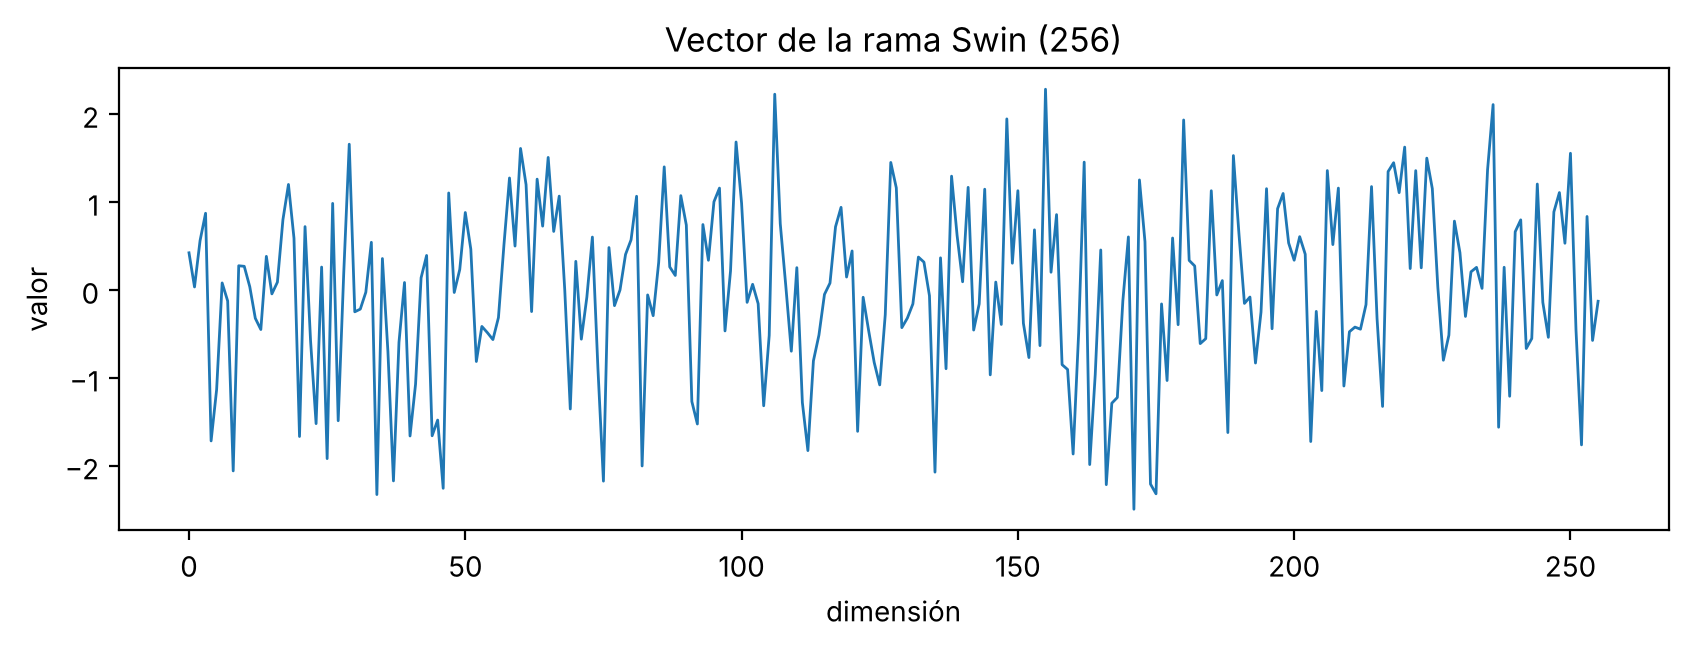

[OK   ] 8 Swin completo  (768 -> 256; 27.52 M parámetros)


In [9]:
from swin import SwinBlock, SwinBranch

swin = SwinBranch()
if CARGAR_IMAGENET:
    from pretrained import load_swin_imagenet
    load_swin_imagenet(swin)
    print("Pesos ImageNet cargados")
swin.eval()

t0 = time.time()
x = swin.patch_embed(face_input)
print(f"{'PatchEmbed':<26} -> {forma(x)}")
etapa, bloque = 1, 0
for lyr in swin.layers:
    x = lyr(x)
    if isinstance(lyr, SwinBlock):
        bloque += 1
        tipo = "SW-MSA" if lyr.s else "W-MSA "
        print(f"  etapa {etapa} bloque {bloque} {tipo}    -> {forma(x)}")
    else:
        print(f"{'PatchMerging':<26} -> {forma(x)}")
        etapa, bloque = etapa + 1, 0
v768 = swin.norm(x).mean(axis=1)
v256 = swin.proj(v768)
print(f"{'LayerNorm + promedio':<26} -> {forma(v768)}")
print(f"{'Proyección 768 -> 256':<26} -> {forma(v256)}")
print(f"Tiempo de un forward: {time.time() - t0:.2f} s")

n_backbone = swin.n_params() - swin.proj.n_params()
print(f"Parámetros: backbone {n_backbone / 1e6:.2f} M + proyección {swin.proj.n_params() / 1e3:.0f} K")
directo = swin(face_input)
v = bk.to_numpy(v256[0])
print(f"Vector 256: mín {v.min():.3f}, máx {v.max():.3f}, media {v.mean():.3f}, norma L2 {np.linalg.norm(v):.3f}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(v, lw=1); ax.set_xlabel("dimensión"); ax.set_ylabel("valor"); ax.set_title("Vector de la rama Swin (256)")
fig.savefig(f"{FIG_DIR}/p08_vector_swin.png", dpi=300, bbox_inches="tight"); plt.show()

comprobar("8 Swin completo", forma(v768) == (1, 768) and forma(v256) == (1, 256)
          and float(xp.abs(directo - v256).max()) < 1e-5 and abs(n_backbone / 1e6 - 27.5) < 0.5,
          f"768 -> 256; {n_backbone / 1e6:.2f} M parámetros")

## 9 Rama CNN lateral: de 224×112 a 256

Tres bloques Conv3×3 + BatchNorm + ReLU + MaxPool2×2 (32, 64 y 128 canales), promedio global y proyección Linear(128→256) + LayerNorm.

In [10]:
from cnn import CNNBranch

cnn = CNNBranch()
cnn.eval()
x = bk.asarray(diff_input)
print(f"{'Mapa diferencial':<20} {forma(x)}")
for k, blk in enumerate(cnn.blocks.mods, 1):
    x = blk(x)
    print(f"{'Bloque ' + str(k):<20} {forma(x)}")
p = cnn.pool(x)
print(f"{'Promedio global':<20} {forma(p)}")
v_cnn = cnn.proj(p)
print(f"{'Proyección':<20} {forma(v_cnn)}")
print(f"Parámetros de la CNN: {cnn.n_params() / 1e3:.1f} K")
comprobar("9 CNN lateral", forma(v_cnn) == (1, 256) and forma(p) == (1, 128), "(1,3,224,112) -> (1,256)")

Mapa diferencial     (1, 3, 224, 112)
Bloque 1             (1, 32, 112, 56)


Bloque 2             (1, 64, 56, 28)
Bloque 3             (1, 128, 28, 14)
Promedio global      (1, 128)
Proyección           (1, 256)
Parámetros de la CNN: 127.0 K
[OK   ] 9 CNN lateral  ((1,3,224,112) -> (1,256))


## 10 Fusión (512) y Branch Dropout

Los dos vectores se concatenan: $z = [z_{swin} \,\|\, z_{cnn}] \in \mathbb{R}^{512}$.
Durante el entrenamiento, con probabilidad 10 % se apaga una de las ramas (5 % cada una), para que ninguna acapare la decisión. En evaluación nunca se apaga.

In [11]:
import random

from detector import DeepfakeDetectorScratch
from mlp import MLPClassifier

fused = xp.concatenate([v256, v_cnn], axis=1)
print("Swin:", forma(v256), "+ CNN:", forma(v_cnn), "->", forma(fused))

# Frecuencia del apagado medida sobre el propio detector, con ramas reducidas para que sea rápido.
chico = DeepfakeDetectorScratch(SwinBranch(img_size=16, patch_size=2, embed_dim=4, depths=(2, 2), num_heads=(2, 2),
                                           window=4, proj_dim=256),
                                CNNBranch(3, (4, 6, 8), proj_dim=256), MLPClassifier(), drop_branch=0.1)
cara_c, mapa_c = bk.randn(1, 3, 16, 16), bk.randn(1, 3, 16, 8)
chico.train()
random.seed(SEED)
n, apaga_g, apaga_l = 4000, 0, 0
for _ in range(n):
    chico(cara_c, mapa_c)
    apaga_g += chico._keep_g == 0.0
    apaga_l += chico._keep_l == 0.0
chico.eval()
chico(cara_c, mapa_c)
en_eval = (chico._keep_g, chico._keep_l)
print(f"Entrenamiento: Swin apagada {100 * apaga_g / n:.1f} %, CNN apagada {100 * apaga_l / n:.1f} %")
print("Evaluación: factores de las ramas =", en_eval)

comprobar("10 Fusión y Branch Dropout", forma(fused) == (1, 512) and abs(apaga_g / n - 0.05) < 0.015
          and abs(apaga_l / n - 0.05) < 0.015 and en_eval == (1.0, 1.0), "≈5 % + 5 % solo en entrenamiento")

Swin: (1, 256) + CNN: (1, 256) -> (1, 512)


Entrenamiento: Swin apagada 4.4 %, CNN apagada 5.1 %
Evaluación: factores de las ramas = (1.0, 1.0)
[OK   ] 10 Fusión y Branch Dropout  (≈5 % + 5 % solo en entrenamiento)


## 11 Clasificador MLP

Linear(512→256) + ReLU + Dropout(0.3) + Linear(256→2). Softmax convierte los logits en probabilidades de real y deepfake.

In [12]:
mlp = MLPClassifier(in_dim=512, hidden_dim=256, num_classes=2, dropout=0.3)
mlp.eval()
logits = mlp(fused)
prob = bk.to_numpy(softmax(logits, axis=1))[0]
print("Entrada:", forma(fused), "-> logits:", forma(logits))
print(f"P(real) = {prob[0]:.4f} | P(deepfake) = {prob[1]:.4f} | suma = {prob.sum():.6f}")
print("(Pesos sin entrenar: la probabilidad aún no significa nada.)")

mlp.train()
a1, a2 = bk.to_numpy(mlp(fused)), bk.to_numpy(mlp(fused))
mlp.eval()
b1, b2 = bk.to_numpy(mlp(fused)), bk.to_numpy(mlp(fused))
print("Dropout activo en entrenamiento:", not np.allclose(a1, a2), "| determinista en evaluación:", np.allclose(b1, b2))
comprobar("11 MLP", forma(logits) == (1, 2) and abs(prob.sum() - 1) < 1e-5 and np.allclose(b1, b2),
          "512 -> 2, softmax suma 1")

Entrada: (1, 512) -> logits: (1, 2)
P(real) = 0.4866 | P(deepfake) = 0.5134 | suma = 1.000000
(Pesos sin entrenar: la probabilidad aún no significa nada.)
Dropout activo en entrenamiento: True | determinista en evaluación: True
[OK   ] 11 MLP  (512 -> 2, softmax suma 1)


## 12 Focal Loss

$FL(p_t) = -\alpha_t (1 - p_t)^{\gamma} \log(p_t)$. El factor $(1-p_t)^\gamma$ reduce el peso de los ejemplos fáciles.
Comprobaciones:
- Con γ = 0 y sin α debe ser igual a la entropía cruzada.
- Un ejemplo fácil debe pesar mucho menos que uno difícil.
- El gradiente analítico debe coincidir con el numérico.
- Debe ser estable con logits extremos.

In [13]:
from losses import FocalLoss

z = bk.asarray(np.array([[2.0, -1.0], [0.3, 0.1], [-1.5, 2.5], [0.0, 0.2]]))
t = xp.asarray([0, 1, 1, 0])
ce = float(-xp.log(softmax(z, axis=1)[xp.arange(4), t]).mean())
fl0, _ = FocalLoss(gamma=0.0, alpha=None)(z, t)
print(f"Entropía cruzada = {ce:.6f} | Focal (γ=0) = {fl0:.6f}")

fl = FocalLoss(gamma=2.0, alpha=0.5)
facil, _ = fl(bk.asarray(np.array([[4.0, -4.0]])), xp.asarray([0]))
dificil, _ = fl(bk.asarray(np.array([[-1.0, 1.0]])), xp.asarray([0]))
print(f"Ejemplo fácil (p_t≈1): {facil:.2e} | difícil (p_t≈0.12): {dificil:.4f}")

bk.set_dtype(np.float64)
z64 = bk.asarray(bk.to_numpy(z))
_, g = fl(z64, t)
num = np.zeros(z64.shape)
for i in range(z64.shape[0]):
    for j in range(z64.shape[1]):
        zp, zm = z64.copy(), z64.copy()
        zp[i, j] += 1e-6; zm[i, j] -= 1e-6
        num[i, j] = (fl(zp, t)[0] - fl(zm, t)[0]) / 2e-6
bk.set_dtype(np.float32)
err = float(np.abs(bk.to_numpy(g) - num).max())
lb, db = fl(bk.asarray(np.array([[800.0, -800.0]])), xp.asarray([1]))
print(f"Error del gradiente: {err:.1e} | pérdida con logits ±800: {lb:.1f} (finita: {np.isfinite(lb)})")

comprobar("12 Focal Loss", abs(ce - fl0) < 1e-5 and facil < dificil / 100 and err < 1e-6
          and np.isfinite(lb) and bool(xp.isfinite(db).all()), "= CE con γ=0; gradiente correcto")

Entropía cruzada = 0.415754 | Focal (γ=0) = 0.415754
Ejemplo fácil (p_t≈1): 1.89e-11 | difícil (p_t≈0.12): 0.8250
Error del gradiente: 2.7e-12 | pérdida con logits ±800: 800.0 (finita: True)
[OK   ] 12 Focal Loss  (= CE con γ=0; gradiente correcto)


## 13 Detector completo de extremo a extremo

`DeepfakeDetectorScratch` recibe el rostro y el mapa y devuelve los logits. `predict_video` promedia P(deepfake) de los 16 fotogramas de un video (etapa 3).
También se prueban las ablaciones (`solo_swin`, `solo_asimetria`) y la máscara lateral por giro de cabeza.

In [14]:
det = DeepfakeDetectorScratch(swin, cnn, mlp, drop_branch=0.1)
det.train()
faces = xp.concatenate([face_input, manip], axis=0)
diffs = bilateral_diff_map(faces, mode="residual")
y = xp.asarray([0, 1])
t0 = time.time()
logits = det(faces, diffs)
loss, dl = FocalLoss(gamma=2.0, alpha=0.5)(logits, y)
det.backward(dl)
sin_grad = [p for p in det.parameters() if p.grad is None or not bool(xp.isfinite(p.grad).all())]
print(f"Forward + backward con B=2: {time.time() - t0:.2f} s | pérdida {loss:.4f}")
print(f"Tensores de parámetros: {len(det.parameters())} | sin gradiente válido: {len(sin_grad)}")
print(f"Parámetros totales: {det.n_params() / 1e6:.2f} M "
      f"(Swin {swin.n_params() / 1e6:.2f} M, CNN {cnn.n_params() / 1e3:.0f} K, MLP {mlp.n_params() / 1e3:.0f} K)")
det.zero_grad(); det.release()

det.eval()
formas = {}
for modo in ("ambas", "solo_swin", "solo_asimetria"):
    det.branches = modo
    formas[modo] = forma(det(faces, diffs))
det.branches = "ambas"
print("Logits por modo:", formas)

lm = np.array([1.0, 0.0], np.float32)
det(faces, diffs, lm)
print("Máscara lateral [1, 0]: la rama lateral del 2.º frame queda en cero:",
      bool(xp.all(det.mlp.net.mods[0].x[1, 256:] == 0)))

video = xp.repeat(face_input, 16, axis=0)
p_video = det.predict_video(video, bilateral_diff_map(video, mode="residual"), chunk=8)
print(f"Video de 16 fotogramas -> P(deepfake) = {p_video:.4f}")

comprobar("13 Detector completo", forma(logits) == (2, 2) and not sin_grad and np.isfinite(loss)
          and all(f == (2, 2) for f in formas.values()) and 0 <= p_video <= 1, "forward, backward, ablaciones y video")

Forward + backward con B=2: 1.22 s | pérdida 0.0843
Tensores de parámetros: 192 | sin gradiente válido: 0
Parámetros totales: 27.98 M (Swin 27.72 M, CNN 127 K, MLP 132 K)


Logits por modo: {'ambas': (2, 2), 'solo_swin': (2, 2), 'solo_asimetria': (2, 2)}


Máscara lateral [1, 0]: la rama lateral del 2.º frame queda en cero: True


Video de 16 fotogramas -> P(deepfake) = 0.5070
[OK   ] 13 Detector completo  (forward, backward, ablaciones y video)


## 14 ¿Aprende? Sobreajuste controlado

Una prueba clásica: con pocos ejemplos, el modelo debe poder memorizarlos y la pérdida tiene que bajar.
Para que corra rápido en CPU se usa la rama de asimetría con AdamW sobre 16 mapas: 8 fotogramas del video vueltos simétricos y los mismos 8 con la mejilla derecha alterada.

[ERROR:0@15.915] global persistence.cpp:584 open Can't open file: '/usr/local/lib/python3.13/site-packages/cv2/data/haarcascade_frontalface_default.xml' in read mode
W0000 00:00:1795210265.617161     292 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
W0000 00:00:1795210265.625409     294 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1795210265.644966     294 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Fotogramas reales del video: 8


Pérdida: paso 1 = 0.0999 -> paso 40 = 0.0000
Exactitud sobre los 16 ejemplos de entrenamiento: 100 %


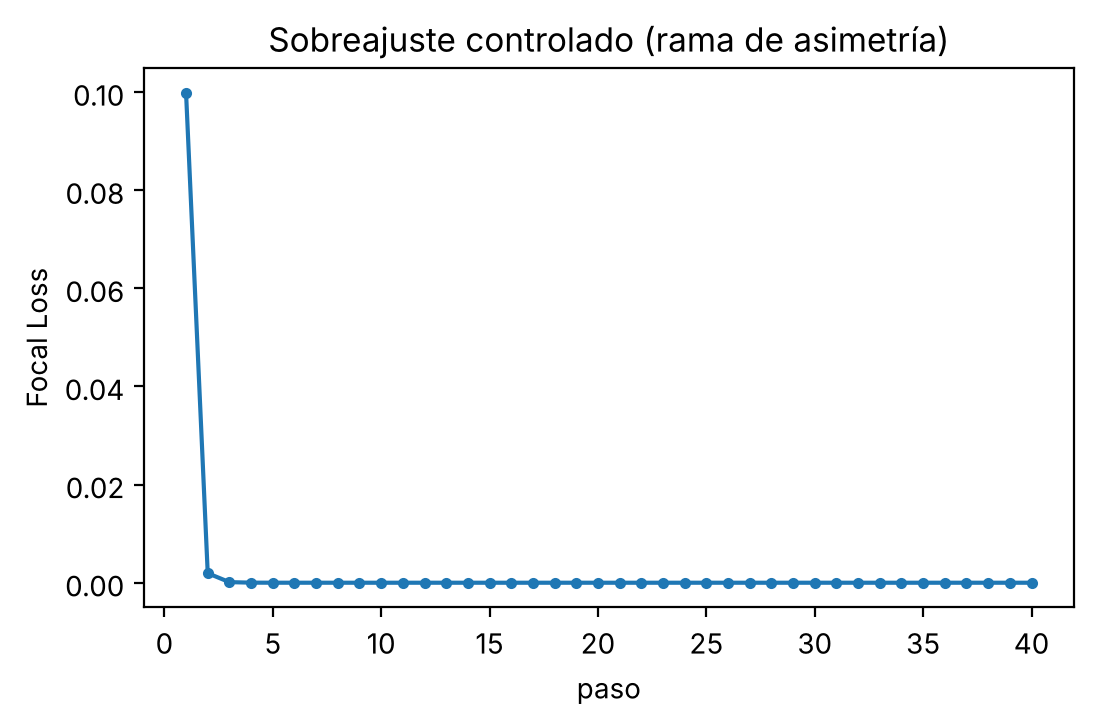

[OK   ] 14 Aprendizaje  (pérdida x0.00)


In [15]:
from optim import AdamW

bk.set_seed(SEED)
if ES_VIDEO:
    from data import FaceAligner, sample_frame_indices
    al = FaceAligner(output_size=224, task_model_path=RUTA_LANDMARKER)
    n_total = int(cv2.VideoCapture(RUTA_ROSTRO).get(cv2.CAP_PROP_FRAME_COUNT))
    caras = []
    for i in sample_frame_indices(n_total, 16):
        c_, _ = al.align(leer_fotograma(RUTA_ROSTRO, i))
        if c_ is not None:
            caras.append(c_)
        if len(caras) == 8:
            break
    al.close()
    print(f"Fotogramas reales del video: {len(caras)}")
else:
    caras = [rostro_sintetico(seed=SEED + k) for k in range(8)]
base = bk.asarray(np.concatenate([c_.transpose(2, 0, 1)[None] / 255.0 for c_ in caras]))
base = simetrizar(base)
alterado = base.copy()
alterado[zona] = gaussian_blur(base, 2.0)[zona]
X = bilateral_diff_map(xp.concatenate([base, alterado]), mode="residual")
Y = xp.asarray([0] * 8 + [1] * 8)

modelo = DeepfakeDetectorScratch(swin, CNNBranch(), MLPClassifier(dropout=0.0), drop_branch=0.0,
                                 branches="solo_asimetria")
params = modelo.cnn.parameters() + modelo.mlp.parameters()
opt = AdamW(params, lr=3e-3, weight_decay=0.0)
crit = FocalLoss(gamma=2.0, alpha=0.5)
sin_cara = xp.zeros((16, 3, 224, 224), bk.DTYPE)   # la rama Swin está desactivada en esta ablación
modelo.train()
hist = []
for paso in range(40):
    modelo.zero_grad()
    logits = modelo(sin_cara, X)
    loss, dl = crit(logits, Y)
    modelo.backward(dl)
    opt.step()
    modelo.release()
    hist.append(loss)
pred = bk.to_numpy(softmax(logits, axis=1))[:, 1]
acierto = float(((pred > 0.5) == bk.to_numpy(Y)).mean())
print(f"Pérdida: paso 1 = {hist[0]:.4f} -> paso 40 = {hist[-1]:.4f}")
print(f"Exactitud sobre los 16 ejemplos de entrenamiento: {100 * acierto:.0f} %")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, 41), hist, marker="o", ms=3); ax.set_xlabel("paso"); ax.set_ylabel("Focal Loss")
ax.set_title("Sobreajuste controlado (rama de asimetría)")
fig.savefig(f"{FIG_DIR}/p14_sobreajuste.png", dpi=300, bbox_inches="tight"); plt.show()
comprobar("14 Aprendizaje", hist[-1] < 0.25 * hist[0] and acierto == 1.0, f"pérdida x{hist[-1] / hist[0]:.2f}")

## 15 Aumento de calidad y normalización robusta

El aumento simula videos de mala calidad (baja resolución, desenfoque, ruido, brillo y contraste) **solo en entrenamiento**.
`RobustNormalizer` calcula la mediana y el IQR por canal **solo con train** y luego se aplica igual a val y test.

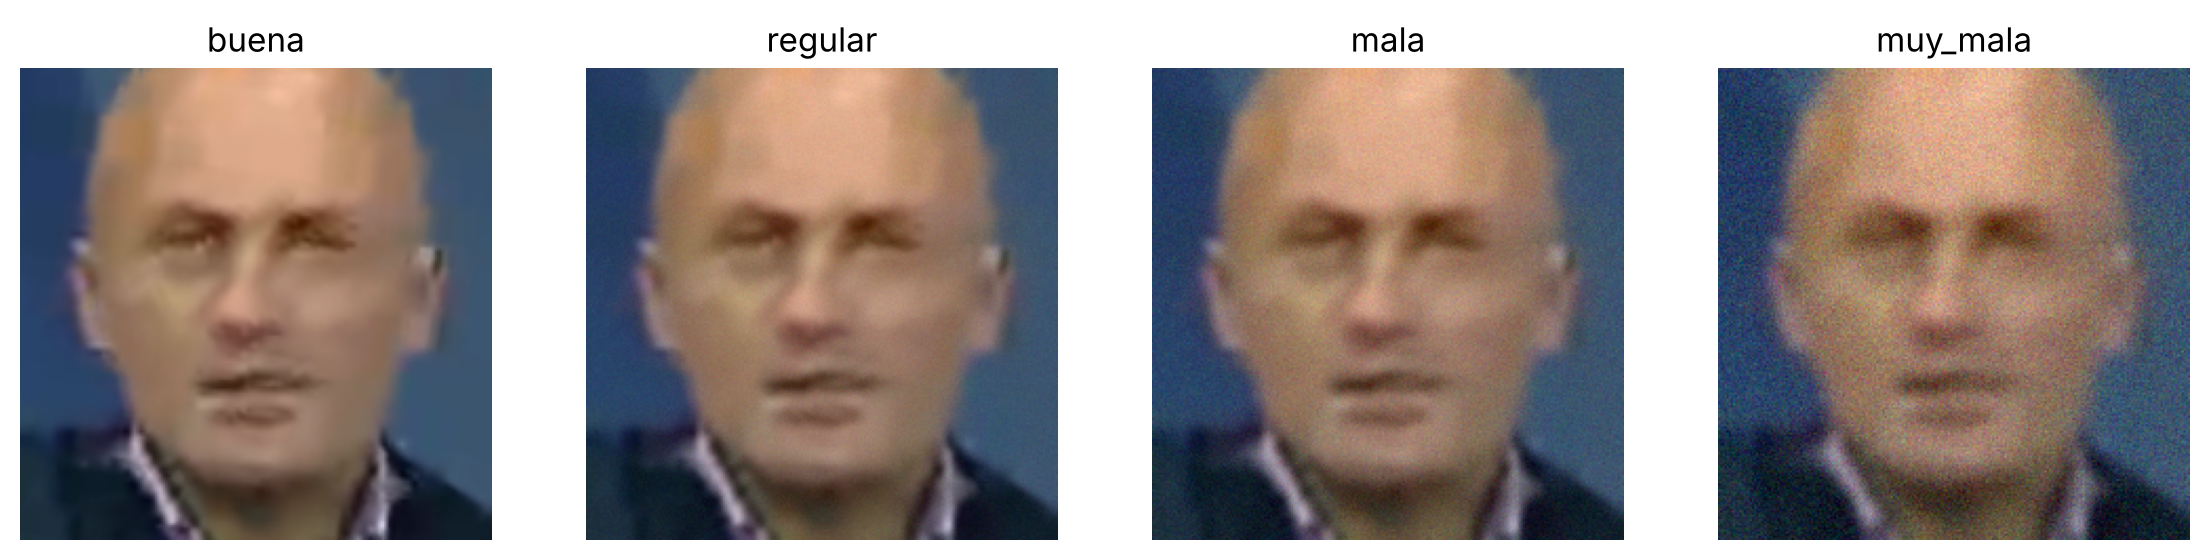

Diferencia media con el original: {'buena': 0.0, 'regular': 0.0102, 'mala': 0.0201, 'muy_mala': 0.0401}
Aumento aleatorio: (4, 3, 224, 224) rango [0.000, 1.000]
Estadísticos de train: mediana [0.459 0.38  0.4  ] | escala [0.273 0.113 0.081]
Tras normalizar train: mediana por canal [0. 0. 0.], rango [-4.9, 5.0]
[OK   ] 15 Calidad y normalización  (degradación creciente; mediana 0 y recorte ±5)


In [16]:
from augment import QUALITY_LEVELS, QualityAugmenter, RobustNormalizer, apply_degradation

niveles = {k: apply_degradation(face_input, spec, seed=0) for k, spec in QUALITY_LEVELS.items()}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
for a_, (k, im) in zip(ax, niveles.items()):
    a_.imshow(np.clip(bk.to_numpy(im[0]).transpose(1, 2, 0), 0, 1)); a_.set_title(k); a_.axis("off")
fig.savefig(f"{FIG_DIR}/p15_niveles_calidad.png", dpi=300, bbox_inches="tight"); plt.show()
dif = {k: float(xp.abs(v - face_input).mean()) for k, v in niveles.items()}
print("Diferencia media con el original:", {k: round(v, 4) for k, v in dif.items()})

np.random.seed(SEED)
aug = QualityAugmenter()(xp.repeat(face_input, 4, axis=0))
print("Aumento aleatorio:", forma(aug), f"rango [{float(aug.min()):.3f}, {float(aug.max()):.3f}]")

train_np = bk.to_numpy(base)
norm = RobustNormalizer(clip=5.0).fit(train_np)
z = bk.to_numpy(norm(base))
print("Estadísticos de train: mediana", np.round(norm.center, 3), "| escala", np.round(norm.scale, 3))
print(f"Tras normalizar train: mediana por canal {np.round(np.median(z, axis=(0, 2, 3)), 3)}, rango [{z.min():.1f}, {z.max():.1f}]")

orden = list(dif.values())
comprobar("15 Calidad y normalización", dif["buena"] == 0 and orden == sorted(orden) and forma(aug) == (4, 3, 224, 224)
          and np.allclose(np.median(z, axis=(0, 2, 3)), 0, atol=1e-3) and np.abs(z).max() <= 5,
          "degradación creciente; mediana 0 y recorte ±5")

## 16 Partición sin fugas de datos

La partición se hace por **video y por identidad**, nunca por fotogramas. Un video falso de FF++ se llama `origen_destino` y combina dos identidades: todas las que estén conectadas deben caer en el mismo conjunto.
Se prueba con una lista simulada de 120 videos reales y 120 falsos.

In [17]:
from data import VideoItem, check_identity_leakage, split_by_identity

rng = np.random.RandomState(SEED)
videos = [VideoItem(f"real/{i:03d}.mp4", 0, "real", f"{i:03d}", (f"{i:03d}",)) for i in range(120)]
for i in range(120):
    j = int(rng.randint(120))
    videos.append(VideoItem(f"fake/{i:03d}_{j:03d}.mp4", 1, "Deepfakes", f"{i:03d}_{j:03d}", (f"{i:03d}", f"{j:03d}")))
splits = split_by_identity(videos, (0.70, 0.15, 0.15), seed=SEED)
fugas = check_identity_leakage(splits)
for k, vs in splits.items():
    print(f"  {k:<5}: {len(vs):3d} videos ({sum(v.label == 0 for v in vs)} reales, {sum(v.label == 1 for v in vs)} falsos)")
print("Identidades y videos compartidos:", fugas)

repetida = split_by_identity(videos, (0.70, 0.15, 0.15), seed=SEED)
mismo = all([v.path for v in splits[k]] == [v.path for v in repetida[k]] for k in splits)
comprobar("16 Partición por identidad", sum(fugas.values()) == 0 and mismo
          and sum(len(v) for v in splits.values()) == 240, "0 identidades compartidas; reproducible con seed 42")

  train:   4 videos (2 reales, 2 falsos)
  val  :   2 videos (1 reales, 1 falsos)
  test : 234 videos (117 reales, 117 falsos)
Identidades y videos compartidos: {'identidades train∩val': 0, 'videos train∩val': 0, 'identidades train∩test': 0, 'videos train∩test': 0, 'identidades val∩test': 0, 'videos val∩test': 0}
[OK   ] 16 Partición por identidad  (0 identidades compartidas; reproducible con seed 42)


## 17 Métricas de evaluación

Se calculan AUC-ROC, F1, precisión, recall, EER y matriz de confusión, más el intervalo de confianza del AUC por bootstrap.
Se prueba con puntajes simulados donde el resultado se conoce.

Separación perfecta: {'auc': 1.0, 'f1': 1.0, 'precision': 1.0, 'recall': 1.0}


  auc       0.954
  f1        0.869
  precision 0.912
  recall    0.830
  accuracy  0.875
  eer       0.140
  umbral de Youden 0.512 | IC 95 % del AUC [0.928, 0.975]
Promedio por video de [0.2, 0.4] y [0.9, 0.7]: [0.3 0.8]


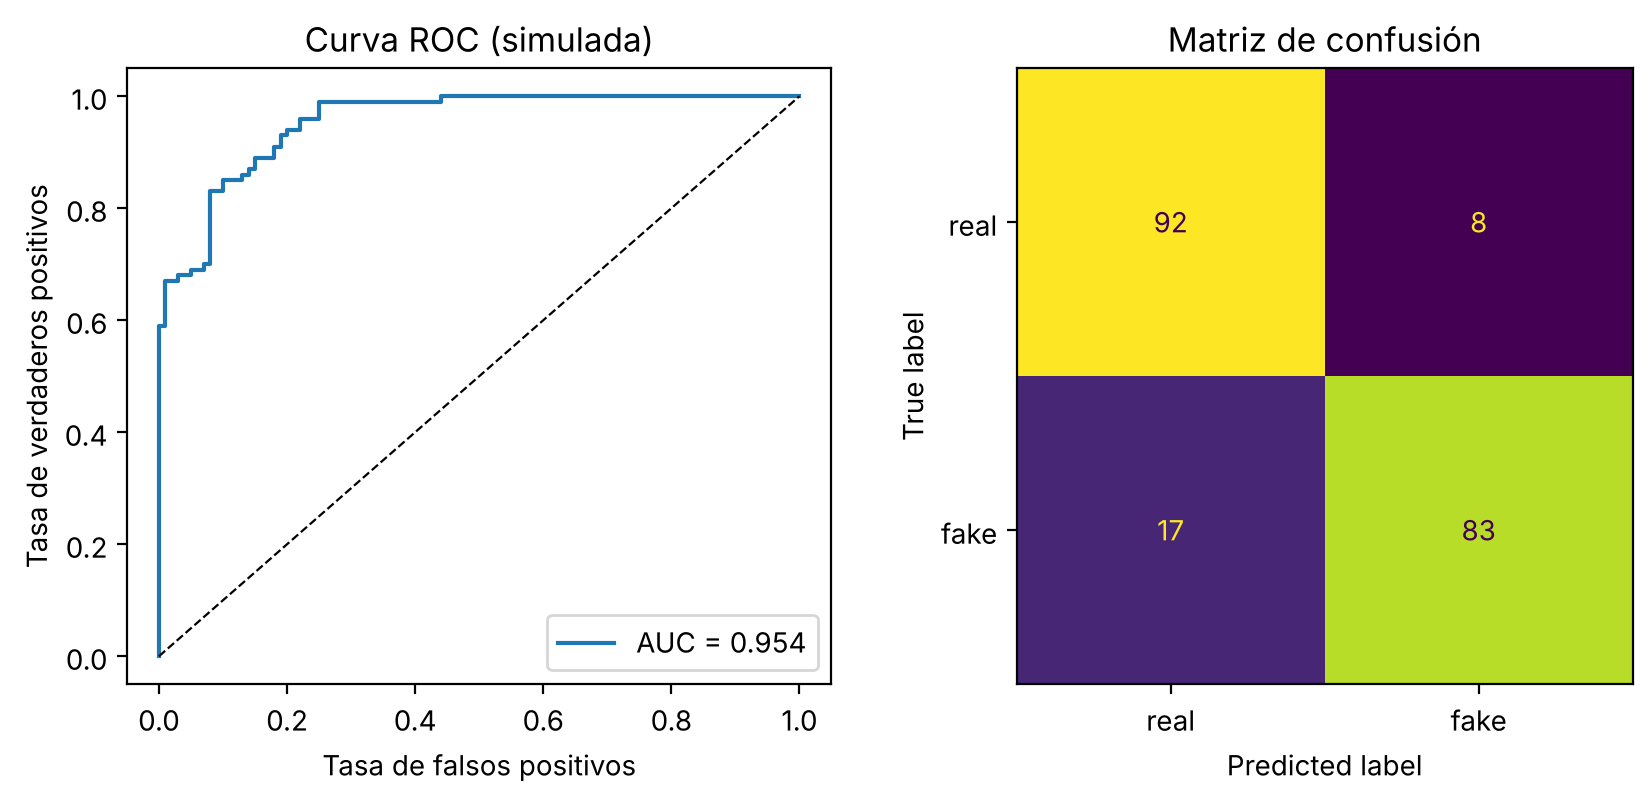

[OK   ] 17 Métricas  (AUC simulado 0.954)


In [18]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

from metrics import binary_metrics, bootstrap_auc, video_scores, youden_threshold

perfecto = binary_metrics(np.array([0, 0, 1, 1]), np.array([0.1, 0.2, 0.8, 0.9]))
print("Separación perfecta:", {k: perfecto[k] for k in ("auc", "f1", "precision", "recall")})

rng = np.random.RandomState(SEED)
y_sim = np.r_[np.zeros(100), np.ones(100)].astype(int)
s_sim = np.clip(np.r_[rng.normal(0.35, 0.15, 100), rng.normal(0.65, 0.15, 100)], 0, 1)
umbral = youden_threshold(y_sim, s_sim)
m = binary_metrics(y_sim, s_sim, umbral)
ic = bootstrap_auc(y_sim, s_sim, n_boot=500)
for k in ("auc", "f1", "precision", "recall", "accuracy", "eer"):
    print(f"  {k:<9} {m[k]:.3f}")
print(f"  umbral de Youden {umbral:.3f} | IC 95 % del AUC [{ic['ic_inf']:.3f}, {ic['ic_sup']:.3f}]")

fv = video_scores(np.array([0.2, 0.4, 0.9, 0.7]), np.array([0, 0, 1, 1]), np.array([0, 1]))
print("Promedio por video de [0.2, 0.4] y [0.9, 0.7]:", fv)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y_sim, s_sim)
ax[0].plot(fpr, tpr, label=f"AUC = {m['auc']:.3f}"); ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos"); ax[0].legend()
ConfusionMatrixDisplay(np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]), display_labels=["real", "fake"]).plot(ax=ax[1], colorbar=False)
ax[0].set_title("Curva ROC (simulada)"); ax[1].set_title("Matriz de confusión")
fig.savefig(f"{FIG_DIR}/p17_metricas.png", dpi=300, bbox_inches="tight"); plt.show()

comprobar("17 Métricas", perfecto["auc"] == 1 and perfecto["f1"] == 1 and 0.85 < m["auc"] < 0.97
          and ic["ic_inf"] < m["auc"] < ic["ic_sup"] and np.allclose(fv, [0.3, 0.8]),
          f"AUC simulado {m['auc']:.3f}")

## 18 Verificación numérica de gradientes

Como el backpropagation está escrito a mano, se compara cada gradiente con diferencias finitas en float64, capa por capa y en el detector completo. Al final se repite el chequeo de dimensiones con los tamaños reales.

In [19]:
import contextlib, io

import gradcheck

salida = io.StringIO()
t0 = time.time()
with contextlib.redirect_stdout(salida):
    try:
        gradcheck.main(); fallo = None
    except SystemExit as e:
        fallo = e.code
texto = salida.getvalue()
print(texto)
bk.set_dtype(np.float32)
n_ok, n_falla = texto.count("[OK"), texto.count("[FALLA")
comprobar("18 Gradientes numéricos", n_falla == 0 and n_ok > 0 and not fallo, f"{n_ok} verificaciones en {time.time() - t0:.0f} s")

Backend: NumPy (CPU) | dtype=float64
1) Gradientes capa por capa
  [OK ] Linear                             out=(3, 7, 4)  err_rel_max=0.00e+00
  [OK ] GELU                               out=(4, 6)  err_rel_max=0.00e+00
  [OK ] LayerNorm                          out=(3, 5, 6)  err_rel_max=0.00e+00
  [OK ] BatchNorm2d (train)                out=(4, 3, 5, 4)  err_rel_max=0.00e+00
  [OK ] Conv2d k3 s1 p1                    out=(2, 4, 6, 5)  err_rel_max=0.00e+00
  [OK ] Conv2d k3 s2 p1 +bias              out=(2, 3, 4, 3)  err_rel_max=0.00e+00
  [OK ] MaxPool2d                          out=(2, 3, 3, 2)  err_rel_max=0.00e+00
  [OK ] GlobalAvgPool2d                    out=(2, 3)  err_rel_max=0.00e+00
  [OK ] PatchEmbedSwin (+LN)               out=(2, 16, 6)  err_rel_max=4.19e-09
  [OK ] WindowAttention (sin máscara)      out=(4, 9, 6)  err_rel_max=0.00e+00
  [OK ] WindowAttention (con máscara)      out=(8, 16, 6)  err_rel_max=0.00e+00
  [OK ] SwinBlock W-MSA (shift=0)          out=(2, 64, 6) 

## Resumen de las pruebas

In [20]:
import pandas as pd

tabla = pd.DataFrame(RESULTADOS, columns=["prueba", "ok", "detalle"])
tabla["resultado"] = tabla["ok"].map({True: "OK", False: "FALLA"})
print(tabla[["prueba", "resultado", "detalle"]].to_string(index=False))
tabla.to_csv(f"{FIG_DIR}/resumen_pruebas.csv", index=False)
print(f"\n{int(tabla['ok'].sum())} de {len(tabla)} pruebas superadas")
assert tabla["ok"].all(), "Hay pruebas que fallaron"

                                            prueba resultado                                             detalle
                                1 Preprocesamiento        OK                              (1,3,224,224) en [0,1]
                                 2a Forma del mapa        OK                                       (1,3,224,112)
                  2b Rostro simétrico da mapa nulo        OK              máx 4.4e-05, error de redondeo float32
2c El mapa localiza una alteración de un solo lado        OK           zona alterada x8 más energía que el resto
                                      3 PatchEmbed        OK                        (1,3136,96); rechaza 220×220
                      4 Partición y reconstrucción        OK                                64 ventanas, error 0
                 5 Máscara de ventanas desplazadas        OK                        (64,49,49), valores {0,-100}
                                6 Window Attention        OK                      filas suman 1;